### WEEK 7: FEATURE SELECTION AND DIMENSIONALITY REDUCTION

#### Project Title
Spotify Music Trends and Audio Features Analysis Using Data Science and Visualization

#### Course
24ADI204 – Data Science and Visualization

#### Team
DSV Team 9

#### Aim
To identify audio features associated with Spotify track popularity and reduce the dimensionality of numerical features using Principal Component Analysis (PCA).

#### Objectives
1. Load the cleaned Spotify dataset.
2. Identify the popularity target and numerical audio features.
3. Examine feature distributions and correlations.
4. Select relevant features using SelectKBest.
5. Standardize features before applying PCA.
6. Calculate and visualize explained variance.
7. Reduce dimensions while retaining at least 90% variance.
8. Export the PCA-transformed dataset.

#### Tools Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

### 1. Importing Required Libraries

Pandas and NumPy are used for data processing and numerical calculations. Matplotlib and Seaborn create visualizations. Scikit-learn provides feature selection, standardization, and Principal Component Analysis (PCA).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_regression

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Loading the Cleaned Spotify Dataset

The cleaned Spotify dataset from Week 3 is loaded using `pd.read_csv()`. The file is named `DSV_Team-9_Cleaned_Dataset.csv`.

The dataset shape and first five rows are displayed to confirm successful loading. The original cleaned file is not modified.

In [2]:
file_name = "DSV_Team-9_Cleaned_Dataset.csv"
candidate_paths = [
    Path.cwd() / file_name,
    Path.cwd() / "processed" / file_name,
    Path.cwd() / "data" / "processed" / file_name,
]
csv_path = next((p for p in candidate_paths if p.is_file()), None)
if csv_path is None:
    print("Dataset not found in the current or processed folders.")
    print("Current folder:", Path.cwd())
    csv_path = Path(input("Enter the full path of your cleaned CSV file: ").strip().strip('"'))
if not csv_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")
df = pd.read_csv(csv_path, low_memory=False)
print("Loaded from:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())


Loaded from: C:\Users\Tejus\processed\spotify_cleaned.csv
Dataset shape: (19335, 45)


,id,artists,available_markets,disc_number,duration_ms.x,explicit,href,is_local,name,popularity,track_number,type.x,uri.x,album.album_type,album.artists,album.available_markets,album.href,album.id,album.images,album.name,album.release_date,album.release_date_precision,album.total_tracks,album.type,album.uri,album.external_urls.spotify,external_ids.isrc,external_urls.spotify,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type.y,uri.y,track_href,analysis_url,duration_ms.y,time_signature
0,000xQL6tZNLJzIrtIgxqSl,https://api.spotify.com/v1/artists/5ZsFI1h6hId...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",1,188490,FALSE,https://api.spotify.com/v1/tracks/000xQL6tZNLJ...,FALSE,Still Got Time (feat. PARTYNEXTDOOR),63,1,track,spotify:track:000xQL6tZNLJzIrtIgxqSl,single,https://api.spotify.com/v1/artists/5ZsFI1h6hId...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",https://api.spotify.com/v1/albums/2kGUeTGnkLOY...,2kGUeTGnkLOYlinKRJe47G,"640, 300, 64, https://i.scdn.co/image/ab67616d...",Still Got Time (feat. PARTYNEXTDOOR),2017-03-23,day,1,album,spotify:album:2kGUeTGnkLOYlinKRJe47G,https://open.spotify.com/album/2kGUeTGnkLOYlin...,USRC11700675,https://open.spotify.com/track/000xQL6tZNLJzIr...,0.748,0.627,7.0,-6.029,1.0,0.0639,0.131000,0.000000,0.0852,0.524,120.963,audio_features,spotify:track:000xQL6tZNLJzIrtIgxqSl,https://api.spotify.com/v1/tracks/000xQL6tZNLJ...,https://api.spotify.com/v1/audio-analysis/000x...,188491.0,4.0
1,001UkMQHw4zXfFNdKpwXAF,https://api.spotify.com/v1/artists/0XKOBt59crn...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",1,191053,FALSE,https://api.spotify.com/v1/tracks/001UkMQHw4zX...,FALSE,Brand New Man - with Luke Combs,68,1,track,spotify:track:001UkMQHw4zXfFNdKpwXAF,album,https://api.spotify.com/v1/artists/0XKOBt59crn...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",https://api.spotify.com/v1/albums/0U3nI78LUpAw...,0U3nI78LUpAwprraUf7vAS,"640, 300, 64, https://i.scdn.co/image/ab67616d...",Reboot,2019-04-05,day,12,album,spotify:album:0U3nI78LUpAwprraUf7vAS,https://open.spotify.com/album/0U3nI78LUpAwprr...,USAN21800051,https://open.spotify.com/track/001UkMQHw4zXfFN...,0.573,0.846,7.0,-4.866,1.0,0.0344,0.003720,0.000079,0.2900,0.562,127.061,audio_features,spotify:track:001UkMQHw4zXfFNdKpwXAF,https://api.spotify.com/v1/tracks/001UkMQHw4zX...,https://api.spotify.com/v1/audio-analysis/001U...,191053.0,4.0
2,003FTlCpBTM4eSqYSWPv4H,https://api.spotify.com/v1/artists/3vAaWhdBR38...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",1,233266,FALSE,https://api.spotify.com/v1/tracks/003FTlCpBTM4...,FALSE,"Swing, Swing",67,3,track,spotify:track:003FTlCpBTM4eSqYSWPv4H,album,https://api.spotify.com/v1/artists/3vAaWhdBR38...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",https://api.spotify.com/v1/albums/0TvOeelcHQXY...,0TvOeelcHQXYgPcyQiLhyR,"640, 300, 64, https://i.scdn.co/image/ab67616d...",The All-American Rejects,2002-10-15,day,11,album,spotify:album:0TvOeelcHQXYgPcyQiLhyR,https://open.spotify.com/album/0TvOeelcHQXYgPc...,USDW10200529,https://open.spotify.com/track/003FTlCpBTM4eSq...,0.553,0.717,7.0,-5.857,1.0,0.0318,0.000065,0.128000,0.0385,0.318,127.947,audio_features,spotify:track:003FTlCpBTM4eSqYSWPv4H,https://api.spotify.com/v1/tracks/003FTlCpBTM4...,https://api.spotify.com/v1/audio-analysis/003F...,233267.0,4.0
3,003vvx7Niy0yvhvHt4a68B,https://api.spotify.com/v1/artists/0C0XlULifJt...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",1,222973,FALSE,https://api.spotify.com/v1/tracks/003vvx7Niy0y...,FALSE,Mr. Brightside,80,2,track,spotify:track:003vvx7Niy0yvhvHt4a68B,album,https://api.spotify.com/v1/artists/0C0XlULifJt...,"AD, AE, AL, AR, AT, AU, BA, BE, BG, BH, BO, BR...",https://api.spotify.com/v1/albums/4piJq7R3gjUO...,4piJq7R3gjUOxnYs6lDCTg,"640, 300, 64, https://i.scdn.co/image/ab67616d...",Hot Fuss,2004,year,12,album,spotify:album:4piJq7R3gjUOxnYs6lDCTg,https://open.spotify.com/album/4piJq7R3gjUOxnY...,USIR20400274,https:/

### 3. Identifying the Target and Candidate Features

The `popularity` column is selected as the target variable. Available numerical audio attributes such as danceability, energy, loudness, valence, and tempo are selected as candidate features.

The target is excluded from the input feature matrix to avoid data leakage.

In [3]:
if "popularity" not in df.columns:
    raise KeyError("The target column 'popularity' is missing.")

candidate_features = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_ms", "duration_ms.x"
]
features = [c for c in candidate_features if c in df.columns]
if not features:
    raise ValueError("No candidate audio features were found in the dataset.")
print("Target: popularity")
print("Available audio features:", features)
print("Number of features:", len(features))


Target: popularity
Available numerical audio features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Number of features: 9


### 4. Preparing the Numerical Feature Matrix

Selected attributes are converted into numerical form. Records with missing popularity values are excluded, and missing feature values are filled with column medians.

The resulting `X` matrix contains the input features, while `y` contains popularity scores.

In [4]:
work = df[features + ["popularity"]].copy()
for col in features + ["popularity"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")
work = work.dropna(subset=["popularity"])
X = work[features].copy()
y = work["popularity"].copy()
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=True) > 1]
X = X.fillna(X.median(numeric_only=True))
features = X.columns.tolist()
if len(features) < 2:
    raise ValueError("At least two valid numerical features are needed for PCA.")
print("Rows used:", len(work))
print("Feature matrix shape:", X.shape)
print("Missing feature values:", int(X.isna().sum().sum()))


Rows used: 19334
Feature matrix shape: (19334, 9)
Missing feature values: 0


### 5. Examining Correlation with Popularity

Pearson correlation is used to examine linear relationships between numerical audio features and popularity. Correlation values range from -1 to +1 and indicate association rather than causation.

### 6. Audio Feature Correlation Heatmap

A heatmap displays pairwise correlations between selected audio features. It helps identify features that vary together and may contain overlapping information.

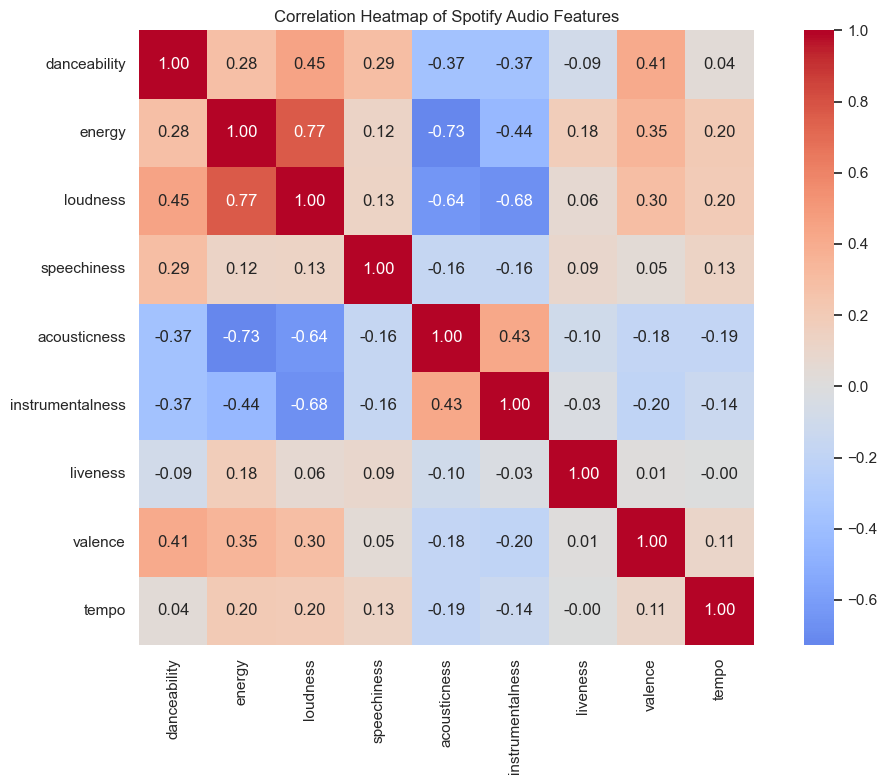

In [5]:
plt.figure(figsize=(11, 8))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Spotify Audio Features")
plt.tight_layout()
plt.show()

### 7. Distribution of Audio Features

Histograms are generated to understand the frequency distribution, spread, and possible skewness of each selected audio feature.

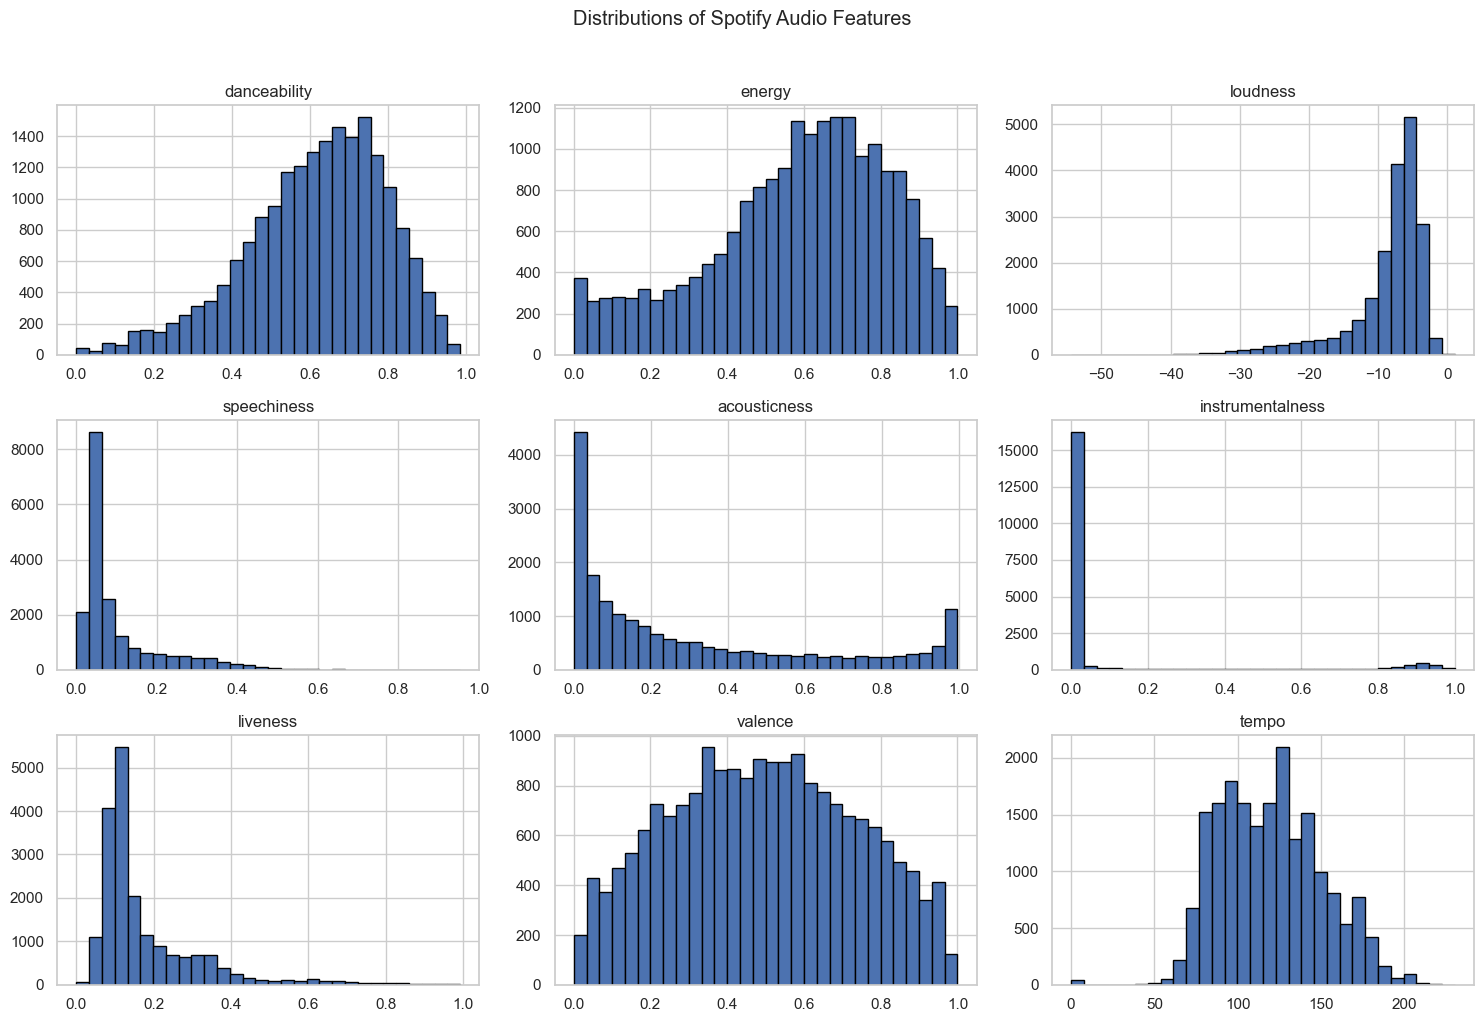

In [6]:
X.hist(figsize=(15, 10), bins=30, edgecolor="black")
plt.suptitle("Distributions of Spotify Audio Features", y=1.02)
plt.tight_layout()
plt.show()

### 8. Boxplot Analysis of Audio Features

Boxplots display medians, quartiles, and potential outliers in the numerical features. Extreme values are inspected visually rather than removed automatically.

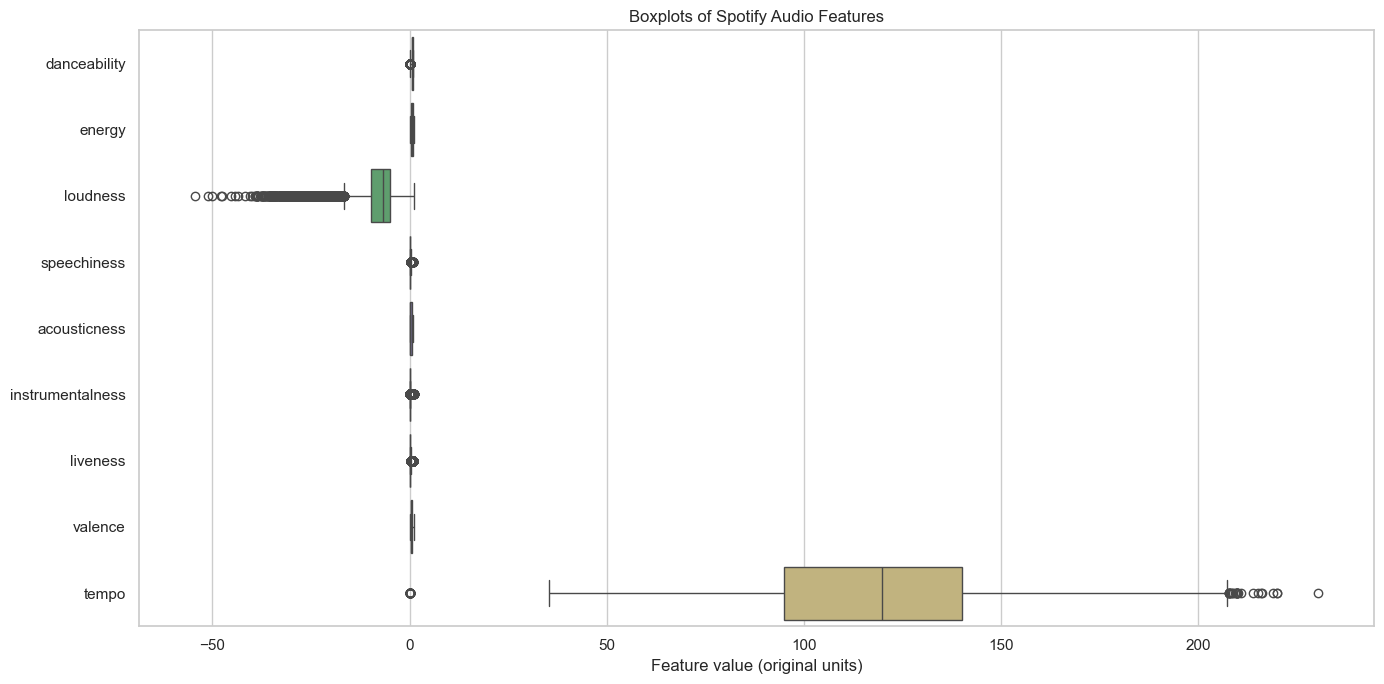

In [7]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=X, orient="h")
plt.title("Boxplots of Spotify Audio Features")
plt.xlabel("Feature value (original units)")
plt.tight_layout()
plt.show()

### 9. Relationship Between Audio Features and Popularity

Scatter plots compare selected audio attributes with popularity scores. A sample of records is used to make the plots easier to interpret.

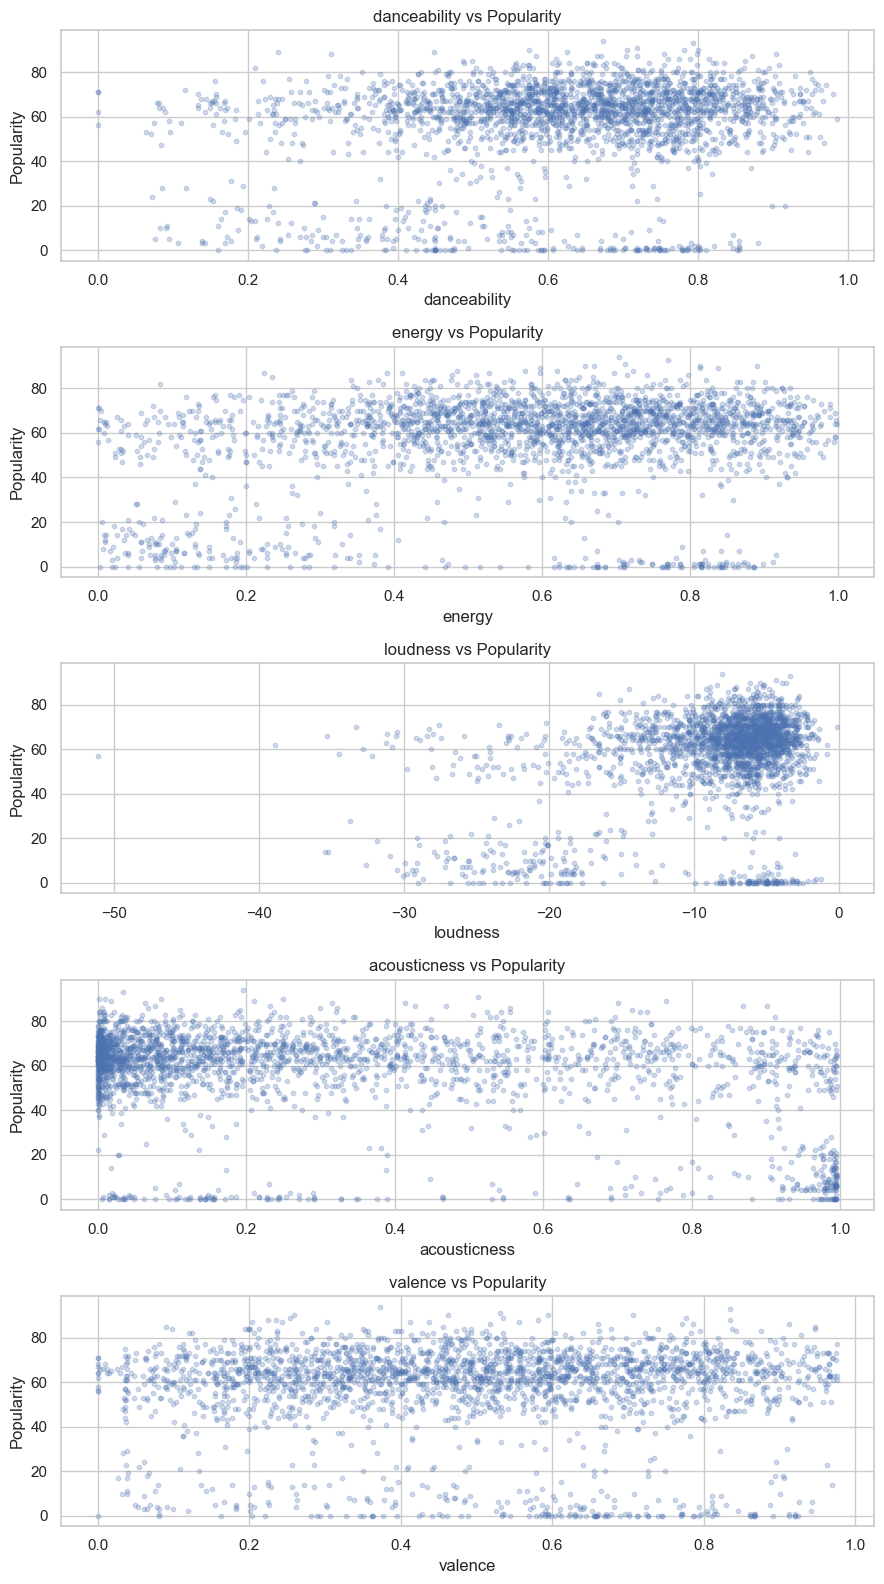

In [8]:
plot_features = [c for c in ["danceability", "energy", "loudness", "acousticness", "valence"] if c in X.columns]
plot_data = work[plot_features + ["popularity"]].sample(n=min(2500, len(work)), random_state=42)
fig, axes = plt.subplots(len(plot_features), 1, figsize=(9, 3.2 * max(1, len(plot_features))))
if len(plot_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, plot_features):
    ax.scatter(plot_data[feature], plot_data["popularity"], alpha=0.25, s=10)
    ax.set_xlabel(feature)
    ax.set_ylabel("Popularity")
    ax.set_title(f"{feature} vs Popularity")
plt.tight_layout()
plt.show()

### 10. Distribution of Spotify Track Popularity

A histogram and density curve are used to examine how popularity scores are distributed across tracks.

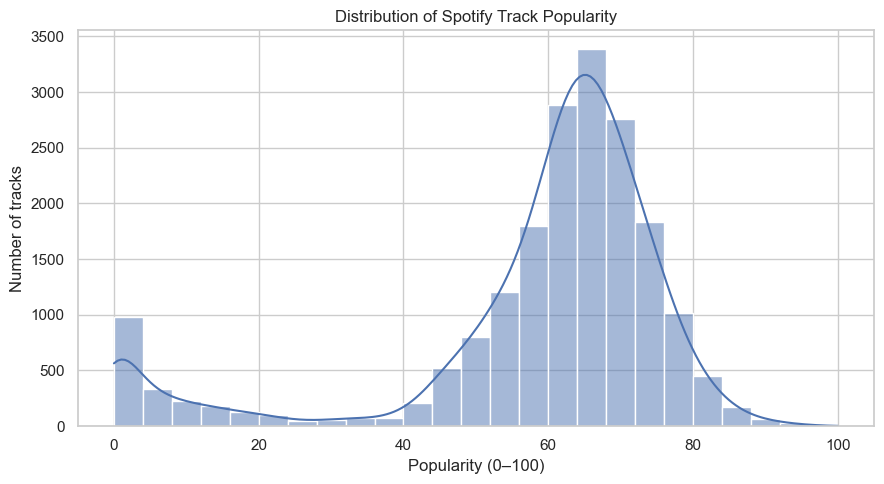

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(y, bins=25, kde=True)
plt.title("Distribution of Spotify Track Popularity")
plt.xlabel("Popularity (0–100)")
plt.ylabel("Number of tracks")
plt.tight_layout()
plt.show()

,correlation_with_popularity
loudness,0.336843
instrumentalness,-0.329840
acousticness,-0.295084
energy,0.240868
danceability,0.177929
tempo,0.067012
speechiness,0.046007
liveness,-0.016148
valence,-0.011686


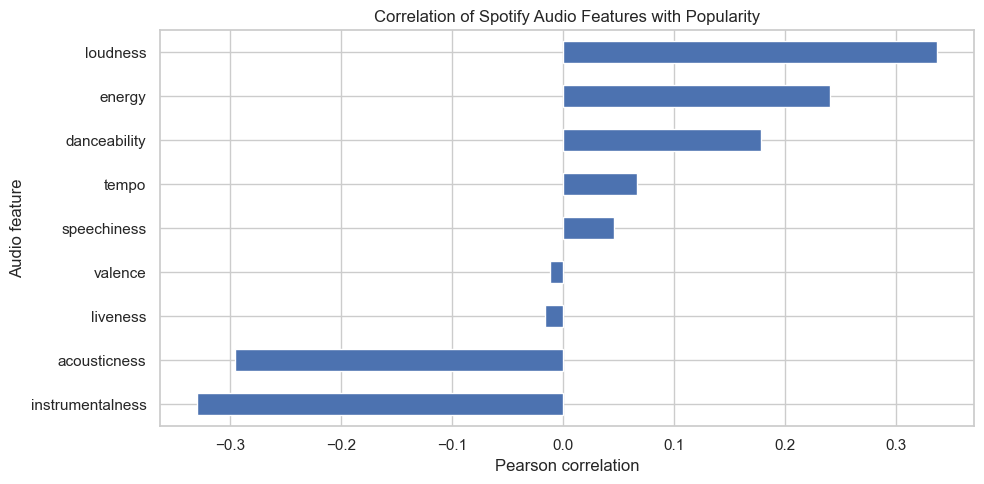

In [10]:
correlations = X.apply(lambda col: col.corr(y)).sort_values(
    key=lambda values: values.abs(), ascending=False
)
display(correlations.rename("correlation_with_popularity").to_frame())

plt.figure(figsize=(10, 5))
correlations.sort_values().plot(kind="barh")
plt.title("Correlation of Spotify Audio Features with Popularity")
plt.xlabel("Pearson correlation")
plt.ylabel("Audio feature")
plt.tight_layout()
plt.show()

### 11. Feature Selection Using SelectKBest

The `SelectKBest` method with `f_regression` evaluates the linear association of each candidate feature with popularity. Up to five features are selected using their statistical scores.

### 12. Visualizing Feature Selection Scores

A horizontal bar chart compares the F-scores of candidate audio features. Higher scores indicate stronger univariate linear associations under this test, but do not establish causation.

,feature,f_score,p_value,selected
0,danceability,632.032407,2.881000e-137,True
1,energy,1190.674114,2.983462e-253,True
2,loudness,2474.201159,0.000000e+00,True
3,speechiness,41.006492,1.552178e-10,False
4,acousticness,1843.886575,0.000000e+00,True
5,instrumentalness,2359.965509,0.000000e+00,True
6,liveness,5.042276,2.474723e-02,False
7,valence,2.640395,1.041939e-01,False
8,tempo,87.203645,1.082305e-20,False


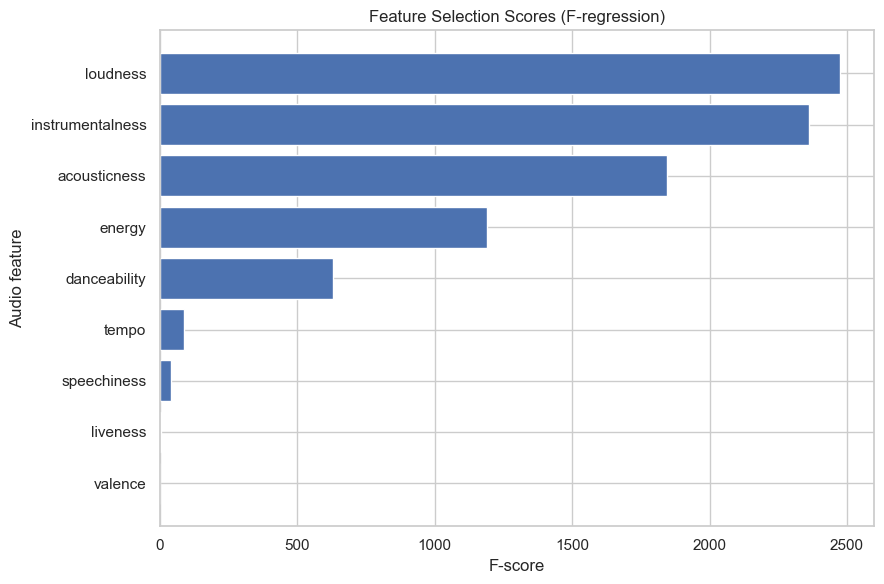

In [12]:
from sklearn.feature_selection import SelectKBest, f_regression
import pandas as pd

selector = SelectKBest(
    score_func=f_regression,
    k=min(5, X.shape[1])
)

selector.fit(X, y)

selection_table = pd.DataFrame({
    "feature": X.columns,
    "f_score": selector.scores_,
    "p_value": selector.pvalues_,
    "selected": selector.get_support()
})

display(selection_table)
score_plot = selection_table.sort_values(
    "f_score", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(score_plot["feature"], score_plot["f_score"])
plt.title("Feature Selection Scores (F-regression)")
plt.xlabel("F-score")
plt.ylabel("Audio feature")
plt.tight_layout()
plt.show()

In [13]:
if features:
    selector = SelectKBest(score_func=f_regression, k=min(5, len(features)))
    selector.fit(X, y)
    selection_table = pd.DataFrame({
        "feature": features,
        "f_score": selector.scores_,
        "p_value": selector.pvalues_,
        "selected": selector.get_support()
    }).sort_values("f_score", ascending=False)
    display(selection_table)
    selected_features = selection_table.loc[selection_table["selected"], "feature"].tolist()
    print("Selected features:", selected_features)
else:
    selected_features = []
    print("No numerical candidate features were found.")

,feature,f_score,p_value,selected
2,loudness,2474.201159,0.000000e+00,True
5,instrumentalness,2359.965509,0.000000e+00,True
4,acousticness,1843.886575,0.000000e+00,True
1,energy,1190.674114,2.983462e-253,True
0,danceability,632.032407,2.881000e-137,True
8,tempo,87.203645,1.082305e-20,False
3,speechiness,41.006492,1.552178e-10,False
6,liveness,5.042276,2.474723e-02,False
7,valence,2.640395,1.041939e-01,False


Selected features: ['loudness', 'instrumentalness', 'acousticness', 'energy', 'danceability']


### 13. Standardizing Features Before PCA

The `StandardScaler` method centers numerical features around zero and scales them to comparable standard deviations. This prevents attributes with larger numerical ranges from dominating PCA.

In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized matrix shape:", X_scaled.shape)
print("Means (rounded):", np.round(X_scaled.mean(axis=0), 3))
print("Standard deviations (rounded):", np.round(X_scaled.std(axis=0), 3))

Standardized matrix shape: (19334, 9)
Means (rounded): [ 0.  0. -0. -0.  0.  0. -0.  0. -0.]
Standard deviations (rounded): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 14. Applying Principal Component Analysis

PCA transforms standardized audio features into new, uncorrelated principal components. The explained variance of each component is calculated to measure how much variation it represents.

In [15]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
variance_table = pd.DataFrame({
    "principal_component": [f"PC{i+1}" for i in range(len(explained))],
    "explained_variance_percent": explained * 100,
    "cumulative_variance_percent": cumulative * 100
})
display(variance_table.round(3))
print("PCA matrix shape:", X_pca.shape)

,principal_component,explained_variance_percent,cumulative_variance_percent
0,PC1,37.985,37.985
1,PC2,12.811,50.795
2,PC3,11.500,62.296
3,PC4,10.791,73.087
4,PC5,9.936,83.022
5,PC6,7.034,90.056
6,PC7,5.316,95.373
7,PC8,3.141,98.513
8,PC9,1.487,100.000


PCA matrix shape: (19334, 9)


### 15. Visualizing Explained and Cumulative Variance

A bar chart shows variance explained by each principal component, while a line shows cumulative explained variance. A 90% reference line helps guide component selection.

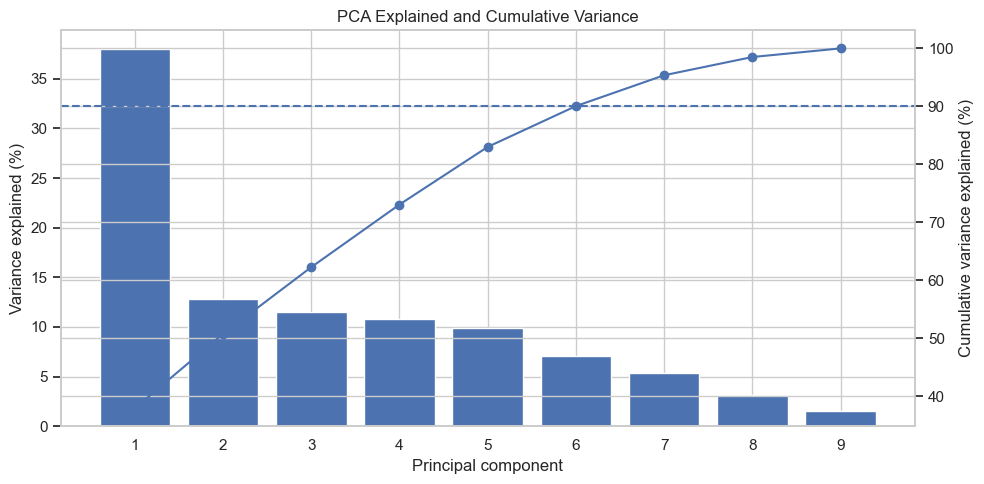

In [16]:
components = np.arange(1, len(explained) + 1)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(components, explained * 100)
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax1.set_xticks(components)
ax2 = ax1.twinx()
ax2.plot(components, cumulative * 100, marker="o")
ax2.set_ylabel("Cumulative variance explained (%)")
ax2.axhline(90, linestyle="--")
plt.title("PCA Explained and Cumulative Variance")
fig.tight_layout()
plt.show()

### 16. Selecting Components That Retain 90% Variance

The smallest number of principal components reaching at least 90% cumulative explained variance is selected. This creates a reduced feature representation while preserving most of the original variation.

### 17. Inspecting PCA Component Loadings

Component loadings show how strongly each original audio feature contributes to the first two principal components. Larger absolute values indicate stronger contributions.

,PC1 loading,PC2 loading
danceability,0.330,-0.526
energy,0.454,0.266
loudness,0.483,0.081
speechiness,0.158,-0.181
acousticness,-0.428,-0.197
instrumentalness,-0.386,0.023
liveness,0.062,0.653
valence,0.255,-0.364
tempo,0.158,0.118


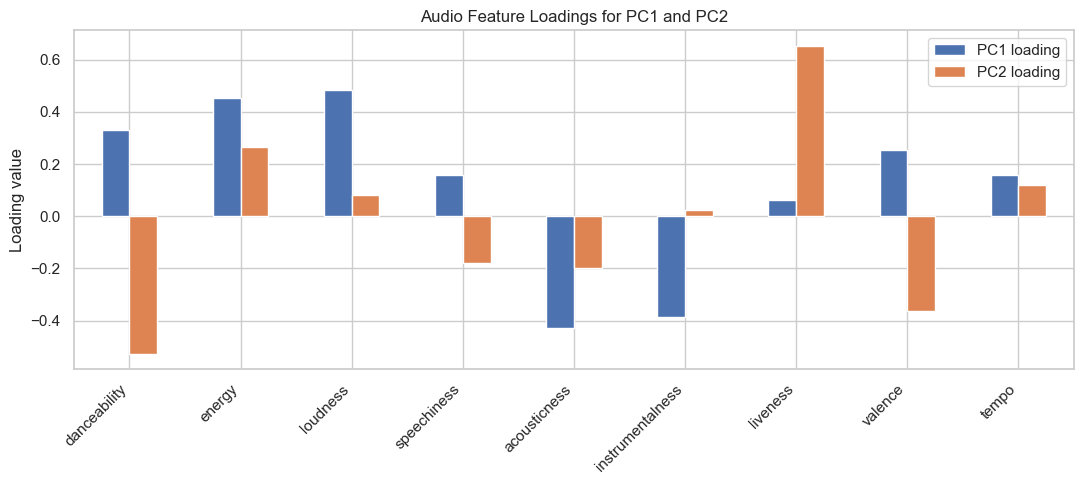

In [17]:
if len(features) >= 2 and pca.components_.shape[0] >= 2:
    loadings = pd.DataFrame(
        pca.components_[:2].T,
        index=features,
        columns=["PC1 loading", "PC2 loading"]
    )
    display(loadings.round(3))
    loadings.plot(kind="bar", figsize=(11, 5))
    plt.title("Audio Feature Loadings for PC1 and PC2")
    plt.ylabel("Loading value")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("At least two features are needed to inspect the first two PCA loadings.")

In [18]:
n_components = int(np.argmax(cumulative >= 0.90) + 1)
pca_reduced = PCA(n_components=n_components)
X_reduced = pca_reduced.fit_transform(X_scaled)
print("Components selected:", n_components)
print("Original feature count:", X.shape[1])
print("Reduced feature count:", X_reduced.shape[1])
print("Variance retained (%):", round(pca_reduced.explained_variance_ratio_.sum() * 100, 2))

Components selected: 6
Original feature count: 9
Reduced feature count: 6
Variance retained (%): 90.06


### 18. Visualizing Tracks in PCA Space

A scatter plot displays tracks using their first two principal components, with color representing popularity. This provides an exploratory view of patterns in the reduced feature space.

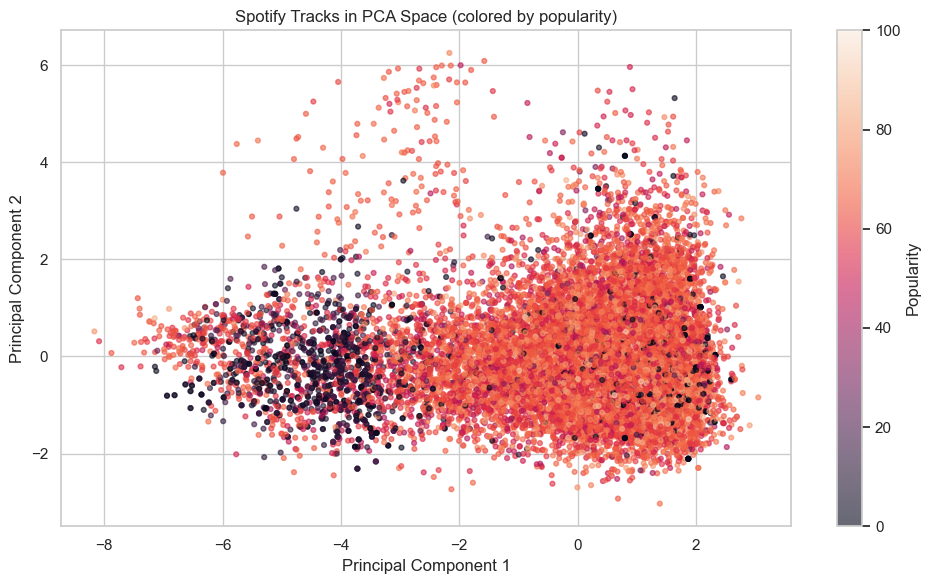

In [19]:
if X_pca.shape[1] >= 2:
    plot_df = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "popularity": y.to_numpy()
    })
    plt.figure(figsize=(10, 6))
    points = plt.scatter(plot_df["PC1"], plot_df["PC2"],
                         c=plot_df["popularity"], s=12, alpha=0.6)
    plt.colorbar(points, label="Popularity")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("Spotify Tracks in PCA Space (colored by popularity)")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical features are needed for a 2D PCA plot.")

### 19. Exporting the PCA-Reduced Dataset

The selected principal components and popularity target are saved as `spotify_pca_week7.csv` inside a `processed` folder. The cleaned input dataset remains unchanged.

In [20]:
pca_columns = [f"PC{i+1}" for i in range(X_reduced.shape[1])]
pca_output = pd.DataFrame(X_reduced, columns=pca_columns, index=work.index)
pca_output["popularity"] = y.to_numpy()
output_dir = Path.cwd() / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "spotify_pca_week7.csv"
pca_output.to_csv(output_path, index=False)
print("PCA dataset saved to:", output_path.resolve())
print("Exported shape:", pca_output.shape)
display(pca_output.head())

PCA dataset saved to: C:\Users\Tejus\Desktop\DSV_PROJECT_TEAM_9\processed\spotify_pca_week7.csv
Exported shape: (19334, 7)


,PC1,PC2,PC3,PC4,PC5,PC6,popularity
0,0.860249,-0.608242,-0.632529,0.214689,-0.283569,0.101697,63.0
1,1.341202,1.168285,-0.691435,-0.059223,0.371941,0.152944,68.0
2,0.431983,0.337178,-1.021492,0.981606,-0.772751,0.814692,67.0
3,0.773686,1.542006,-0.665979,1.618133,-0.862515,0.597694,80.0
4,1.686725,-0.218063,-0.734654,0.248227,0.342786,0.278950,68.0


### 20. Conclusion

Feature selection and dimensionality reduction were performed on the cleaned Spotify dataset. Numerical audio features were examined through distributions, scatter plots, and correlation analysis. `SelectKBest` was used to identify features associated with popularity, and `StandardScaler` was applied before PCA.

Explained variance was analyzed, a reduced representation retaining at least 90% variance was created, and the resulting dataset was exported for further analysis.

#### Result
Feature selection, PCA, and visualization were completed, and a reduced Spotify dataset was prepared for subsequent analysis.